In [1]:
#General tolls
import numpy as np
import pandas as pd
import seaborn as sns
import os
import pymol2

#Coded tools, you need to connect it manually sometimes
from generate_graph_new import protein_pocket, make_protein_ligand_complex

#Heatmap tools
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap



In [55]:
#Prepare pocket docking

#Fixed data
dock_pdbqt_dir = '/data/projects/Chemdocking/dock_score/docking_result/'
protein_pdb_dir = "/data/projects/Chemdocking/VirtualDockingLab/data/screen_8000/protein/target.pdb"
complex_pdb_dir = "tmp/complex.pdb"
complex_csv_dir = "complex.csv"
pocket_dir = '/projectbig/jupyternotebook/jrivera/Output/pocket_results'

for files in os.listdir(dock_pdbqt_dir):

    if files.split('.') [1] != 'pdbqt':
        continue

    os.mkdir("tmp") #make folder for tmp

    # Make ligand pose path
    docking_dir = os.path.join(dock_pdbqt_dir, files)

    # Conver ligand posed pdb file to several sdf files
    ! /home/jrivera/envs/chem/bin/obabel {docking_dir} -O tmp/ligand_pose_.sdf -m

    # Make cprotein-ligand complex file (take the first ligand pose)
    make_protein_ligand_complex(protein_pdb_dir, "tmp/ligand_pose_1.sdf", complex_pdb_dir)

    pocket = protein_pocket(complex_pdb_dir, ligand_id = 'UNK', threshold = 6)

    csv_file_name = files.split('.')[0] + '.csv'
    docking_dir = os.path.join(pocket_dir, csv_file_name)
    pocket.to_csv(docking_dir)
    
    os.system("rm -r tmp")  #remove the folder because we dont need it anymore

print ('All done')

9 molecules converted
9 files output. The first is tmp/ligand_pose_1.sdf
9 molecules converted
9 files output. The first is tmp/ligand_pose_1.sdf
9 molecules converted
9 files output. The first is tmp/ligand_pose_1.sdf
9 molecules converted
9 files output. The first is tmp/ligand_pose_1.sdf
*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is /data/projects/Chemdocking/dock_score/docking_result/dock_smina_PAH_6N1K_Sepiapterin_v1.pdbqt)

*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is /data/projects/Chemdocking/dock_score/docking_result/dock_smina_PAH_6N1K_Sepiapterin_v1.pdbqt)

*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is /data/projects/Chemdocking/dock_score/docking_result/dock_smina_PAH_6N1K_Sepiapterin_v1.pdbqt)

*** Open Babel Warning  in PerceiveBondOrders
  Failed to

In [66]:
#Ligand preparation for heatmap

#Define your directory
pocket= '/projectbig/jupyternotebook/jrivera/Output/pocket_results'

#List the files on your directory, needed for csv files filtering
pocket_data_file_names = os.listdir(pocket_dir)        

#Create a dictionary to save your data
PAH_ligands= {}

#Create a loop to filter, open/read, and process your data, then add it to the dictionary
#For my variable in the pocket data; split items after the . 
#if they are not equal to csv, ignore them

for filename in pocket_data_file_names:             
    if filename.split('.') [1] != 'csv':
        continue                         

    #Open only the filtered files
    pocket_dir = os.path.join(pocket, filename)  

    #Read your filtered files    
    ligands = pd.read_csv(pocket_dir)

    #Create a binary data set to represt the data in a heat map
    #Create a range 0 to 452
    #Extract the values of the colums of the indexa dn compare them to the positions of your range
    #If there are present, change the 0 for a 1
    ligands_processed = [1 if i in list(ligands['index']) else 0 for i in range(453)]

    #Add the data for your dictionary   
    #Select only the file name as the key of the dictionary
    #Put our processed data in the values    
    PAH_ligands[filename.split('_')[4]] = ligands_processed
    
    # print (PAH_ligands)

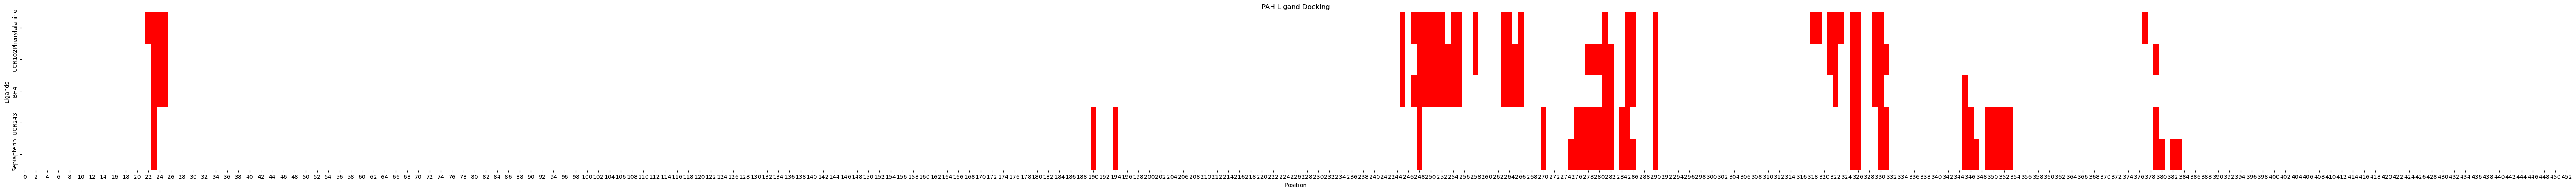

In [67]:
#Make the heatmap

#Make your dictionary a panda data frame
#Transpose it to have the desired visualization

heatmap_PAH_ligands = pd.DataFrame(PAH_ligands).T

plt.figure(figsize=(80, 5))
sns.heatmap(heatmap_PAH_ligands, cmap=["white", "red"], cbar=False, linewidths=0.001, linecolor='gray')

xticks = list(range(0, 453, 2))


plt.title('PAH Ligand Docking')
plt.xlabel('Position')
plt.ylabel('Ligands')



plt.savefig('/projectbig/jupyternotebook/jrivera/Output/figures/Docking/Ligand_controls.pdf')
plt.show()